# Machine Learning as an Aid Against Phishing and Fraud
---
## Authors:
Alan Becker,
Alexander Zambie,
Brennan Slate,
and Lazaro Martinez Jimenez


# Introduction

A phishing email is a fraudulent message from a cybercriminal who impersonates a trusted source to trick you into revealing sensitive information, such as passwords, credit card numbers, or bank details. In this report predictions will be made to distiguish if an email is phishing/fraudulent, or a real email.


## Dataset Choice
This project is using the [Phishing Email Dataset](https://www.kaggle.com/datasets/naserabdullahalam/phishing-email-dataset) from Kaggle. This dataset contains approximately 82,500 emails, with 42,891 labeled as phishing and 39,595 as legitimate. The emails are sourced from Enron, Ling, CEAS, Nazario, SpamAssassin, and Nigerian Fraud emails. For this project, we will focus on the CEAS subset, as it provides more relevant features and is less dated.


## Prediction Goal and Features
The goal of this project is to compare different machine learning models that can distinguish between phishing and legitimate emails based on their content.


We plan to use the columns `subject`, `body`, `sender`, and `urls` to predict the `label` column, which indicates whether an email is phishing or legitimate.









In [344]:
# packages
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.metrics import cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
import xgboost as xgb

## Read Data

In [321]:
df = pd.read_csv('data/CEAS_08.csv')

# Data Exploration and Cleaning

Looking at the data, there are 2 columns with missing values. 462 instances in the "receiver" column, and 28 in the "subject" column. Majority of the types are objects, with labesl and url's being int64.



In [322]:
na_per_col = df.isna().sum().sort_values(ascending=False)
print(na_per_col)
print(df.info())

receiver    462
subject      28
sender        0
date          0
body          0
label         0
urls          0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39154 entries, 0 to 39153
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sender    39154 non-null  object
 1   receiver  38692 non-null  object
 2   date      39154 non-null  object
 3   subject   39126 non-null  object
 4   body      39154 non-null  object
 5   label     39154 non-null  int64 
 6   urls      39154 non-null  int64 
dtypes: int64(2), object(5)
memory usage: 2.1+ MB
None


## Data Preprocessing


Preparing the data for modeling by dropping unnecessary columns and handling missing values. Receiver and date will be dropped, as they do not have much impact on determining if an email is phishing or legitimate. Also filled the NA values of subject with ''. Also the Object types of sender, receiver, subject, and url's were changed to strings for future use. 

In [323]:
df = df.drop(["receiver", "date"], axis=1)
df = df.fillna('')
df["urls"] = df["urls"].astype("string").fillna("").str.strip()
df["sender"] = df["sender"].astype("string").fillna("").str.strip()
df["subject"] = df["subject"].astype("string").fillna("").str.strip()


## Data Exploration and Visualization


In [324]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39154 entries, 0 to 39153
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   sender   39154 non-null  string
 1   subject  39154 non-null  string
 2   body     39154 non-null  object
 3   label    39154 non-null  int64 
 4   urls     39154 non-null  string
dtypes: int64(1), object(1), string(3)
memory usage: 1.5+ MB


,sender,subject,body,label,urls
0,Young Esposito <Young@iworld.de>,Never agree to be a loser,"Buck up, your troubles caused by small dimensi...",1,1
1,Mok <ipline's1983@icable.ph>,Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these te...,1,1
2,Daily Top 10 <Karmandeep-opengevl@universalnet...,CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1,1
3,Michael Parker <ivqrnai@pobox.com>,Re: svn commit: r619753 - in /spamassassin/tru...,Would anyone object to removing .so from this ...,0,1
4,Gretchen Suggs <externalsep1@loanofficertool.com>,SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7...,1,1


# Count Plot of Features

Although there are imbalances in the distribution of some of these features, they capture meaningful behavioral differences between legitimate and phishing emails, so these features are kept for modeling.

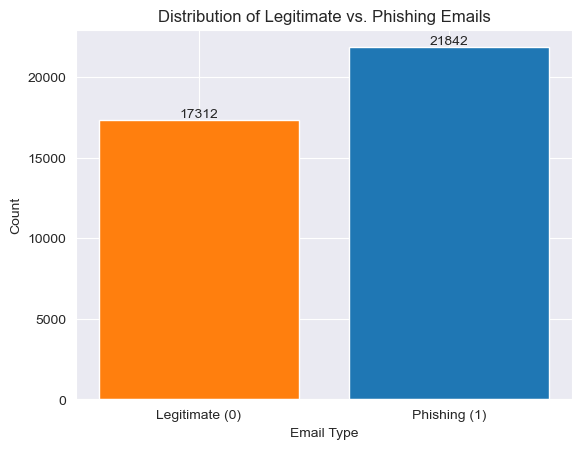

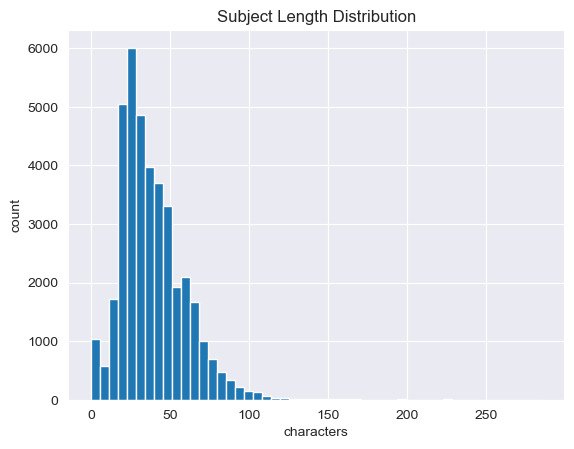

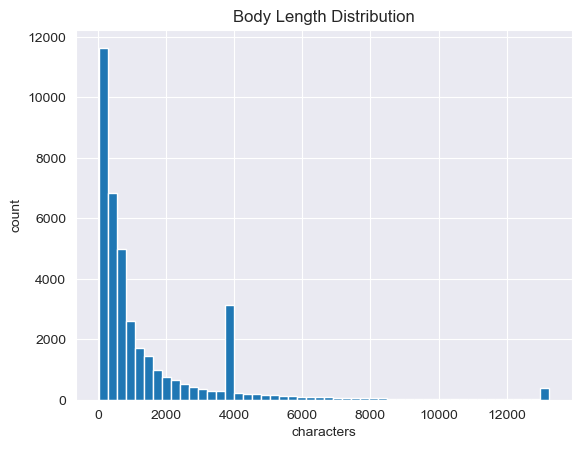

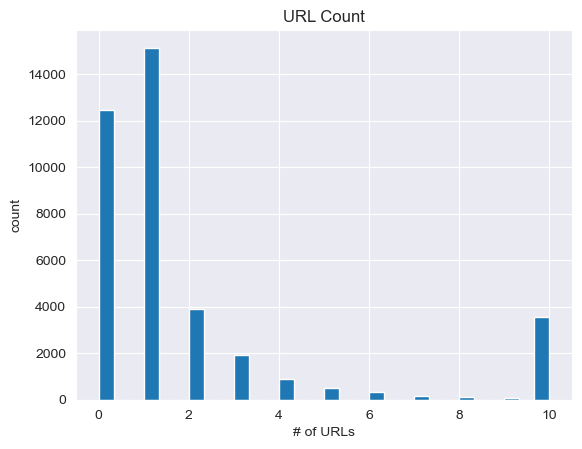

In [342]:
url_pattern = r"(https?://|www\.)\S+" 

df["n_urls"] = (
    df["urls"].str.count(url_pattern) +
    df["subject"].str.count(url_pattern) +
    df["body"].str.count(url_pattern)
)

df["subject_len"] = df["subject"].str.len()
df["body_len"] = df["body"].str.len()

bar_colors = ['#1f77b4', '#ff7f0e']

# Legit vs Phishing Count
count = df['label'].value_counts()
bars = plt.bar(count.index, count.values, color=bar_colors)
plt.title('Distribution of Legitimate vs. Phishing Emails')
plt.xlabel('Email Type')
plt.ylabel('Count')
plt.xticks([0, 1], ['Legitimate (0)', 'Phishing (1)'])
plt.bar_label(bars, fmt='%d', fontsize=10)
plt.show()

# Subject length
plt.figure()
df["subject_len"].plot(kind="hist", bins=50)
plt.title("Subject Length Distribution")
plt.xlabel("characters")
plt.ylabel("count")
plt.show()

#Body length
plt.figure()
df["body_len"].clip(upper=df["body_len"].quantile(0.99)).plot(kind="hist", bins=50)
plt.title("Body Length Distribution")
plt.xlabel("characters")
plt.ylabel("count")
plt.show()

# URL's per email count
plt.figure()
df["n_urls"].clip(upper=10).plot(kind="hist", bins=30)
plt.title("URL Count")
plt.xlabel("# of URLs")
plt.ylabel("count")
plt.show()



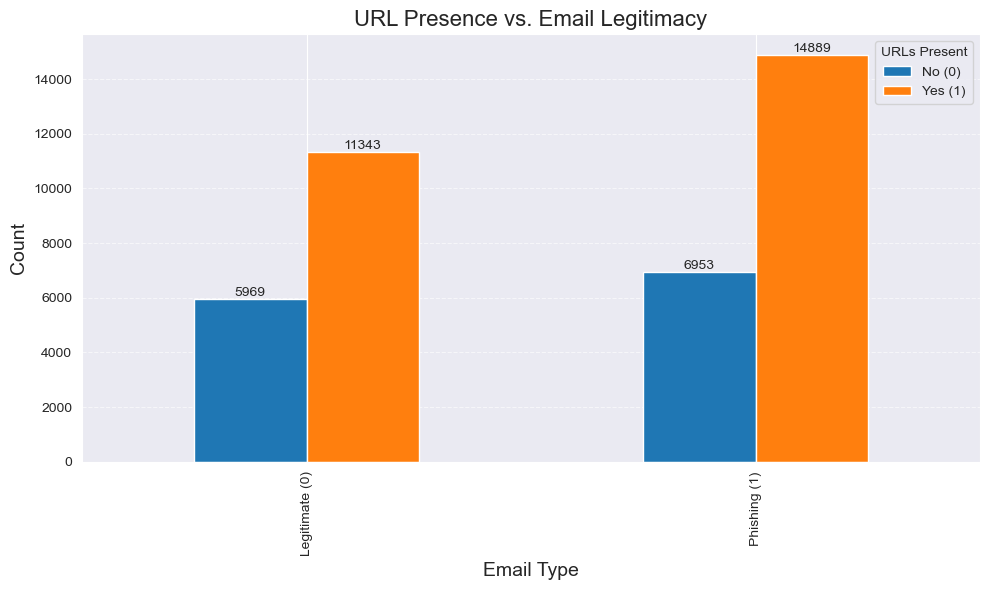

In [343]:
plot_data = pd.crosstab(df['label'], df['urls'])
fig, ax = plt.subplots(figsize=(10, 6))
plot_data.plot(kind='bar', ax=ax, color=bar_colors)
ax.set_title('URL Presence vs. Email Legitimacy', fontsize=16)
ax.set_xlabel('Email Type', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
ax.legend(title='URLs Present', labels=['No (0)', 'Yes (1)'], loc='upper right')
for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Machine Learning Models


In [327]:
df['predictor'] = (df['subject'] + ' ' + df['body'] + ' ' + df['sender']) + ' ' + df['urls'].astype(str)
vectorizer = TfidfVectorizer()
X = df['predictor']
y = df['label'].values
# Splitting the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Applying TFIDF vectorizer after splitting the data
X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

In [328]:
# Function to evaluate models
def eval_model(model, X_train, y_train, X_test, y_test):
    start_time = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start_time

    pred_time_start = time.time()
    y_pred = model.predict(X_test)
    pred_time = time.time() - pred_time_start

    # Use predict_proba or decision_function for probabilities depending on the model
    if hasattr(model, "predict_proba"):
      y_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
      y_prob = model.decision_function(X_test)
    else:
      raise ValueError("model does not use predict_proba or decision_function method.")

    model_names = {
      "MultinomialNB": "Naive Bayes",
      "LogisticRegression": "Logistic Regression",
      "KNeighborsClassifier": "K-Nearest Neighbors",
      "RandomForestClassifier": "Random Forest",
      "LinearSVC": "Linear SVC",
      "XGBClassifier": "XGBoost"
    }

    train_score = model.score(X_train, y_train)
    test_score = model.score(X_test, y_test)

    # Confusion Matrix
    labels = sorted(np.unique(y_test))
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(values_format="d", cmap="Blues")
    plt.title(f"Confusion Matrix for {model_names[model.__class__.__name__]}")
    plt.show()

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_nb = roc_auc_score(y_test, y_prob)

    plt.figure()
    plt.plot(fpr, tpr, label=f"{model_names[model.__class__.__name__]} (AUC = {auc_nb:.2f})")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve for {model_names[model.__class__.__name__]}")
    plt.legend(loc="lower right")
    plt.show()

    # Model performance metrics
    print(f"Model Training Time: {train_time:.4f} seconds")
    print(f"Prediction Time: {pred_time:.4f} seconds")
    print("Train Accuracy: {:.2f}%".format(train_score*100))
    print("Test Accuracy: {:.2f}%".format(test_score*100))
    print("Cohen's Kappa:", round(cohen_kappa_score(y_test, y_pred), 3))
    print(model_names[model.__class__.__name__] + " Classification Report")
    print(classification_report(y_test, y_pred, zero_division=0))


## KNN (K-Nearest Neighbors) Approach

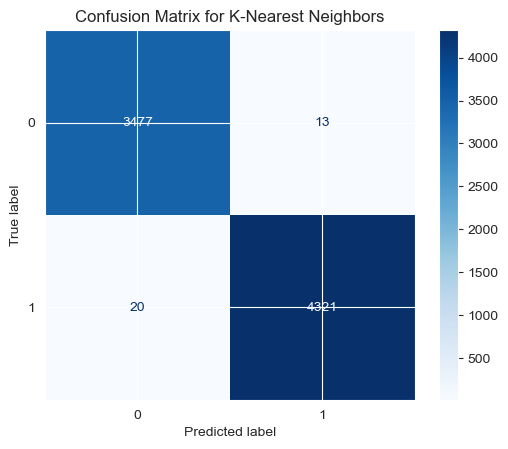

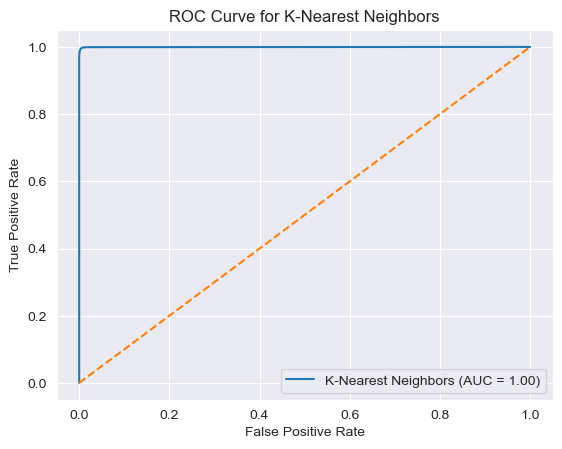

Model Training Time: 0.0121 seconds
Prediction Time: 10.6157 seconds
Train Accuracy: 99.64%
Test Accuracy: 99.58%
Cohen's Kappa: 0.991
K-Nearest Neighbors Classification Report
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      3490
           1       1.00      1.00      1.00      4341

    accuracy                           1.00      7831
   macro avg       1.00      1.00      1.00      7831
weighted avg       1.00      1.00      1.00      7831



In [329]:
knn_model = KNeighborsClassifier()
eval_model(knn_model, X_train, y_train, X_test, y_test)

## Naives Bayes Approach

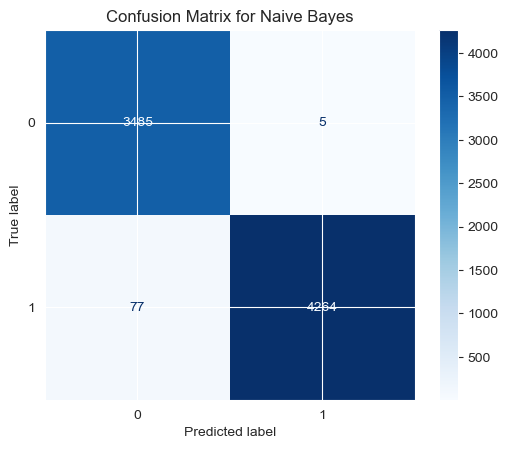

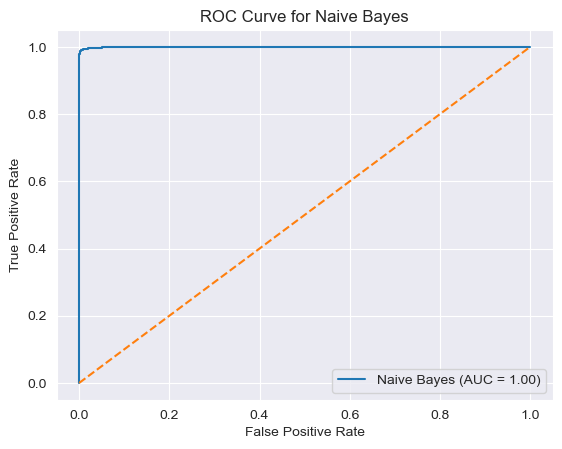

Model Training Time: 0.0218 seconds
Prediction Time: 0.0049 seconds
Train Accuracy: 99.12%
Test Accuracy: 98.95%
Cohen's Kappa: 0.979
Naive Bayes Classification Report
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3490
           1       1.00      0.98      0.99      4341

    accuracy                           0.99      7831
   macro avg       0.99      0.99      0.99      7831
weighted avg       0.99      0.99      0.99      7831



In [330]:
naivebayes_model = MultinomialNB()
eval_model(naivebayes_model, X_train, y_train, X_test, y_test)

## Logistic Regression Approach


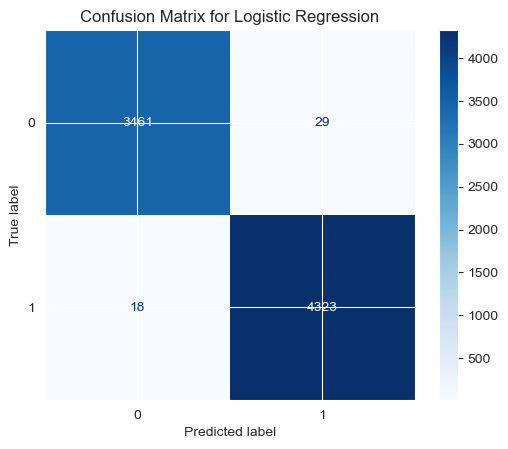

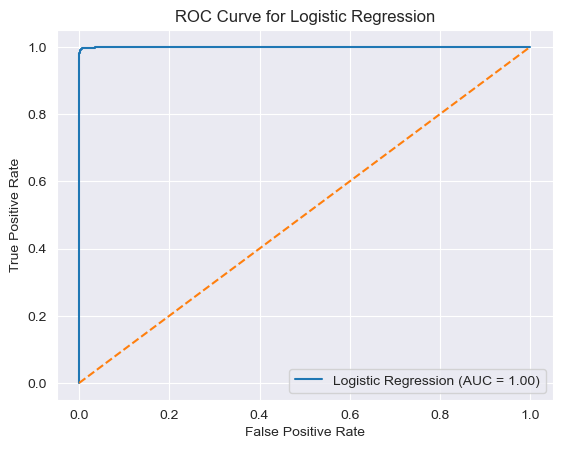

Model Training Time: 0.7857 seconds
Prediction Time: 0.0028 seconds
Train Accuracy: 99.54%
Test Accuracy: 99.40%
Cohen's Kappa: 0.988
Logistic Regression Classification Report
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3490
           1       0.99      1.00      0.99      4341

    accuracy                           0.99      7831
   macro avg       0.99      0.99      0.99      7831
weighted avg       0.99      0.99      0.99      7831



In [331]:
model = LogisticRegression()
eval_model(model, X_train, y_train, X_test, y_test)

# Confusion Matrix


The confusion matrix shows how our Logistic Regression model tells the difference between legitimate and phishing emails. Out of all legitimate emails, only 29 were misclassified as phishing, while 971 were correctly identified as legitimate. And then out of all phishing emails, 982 were correctly detected as phishing, and only 18 were mistakenly labeled as legitimate.

These results show that the model works really well in both detexting phishing and legitimate emails.

# Random Forest Model

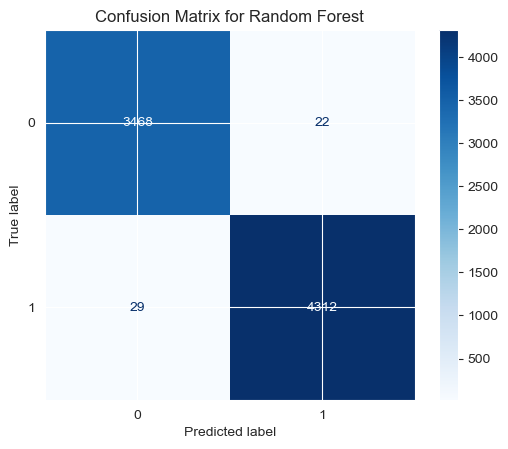

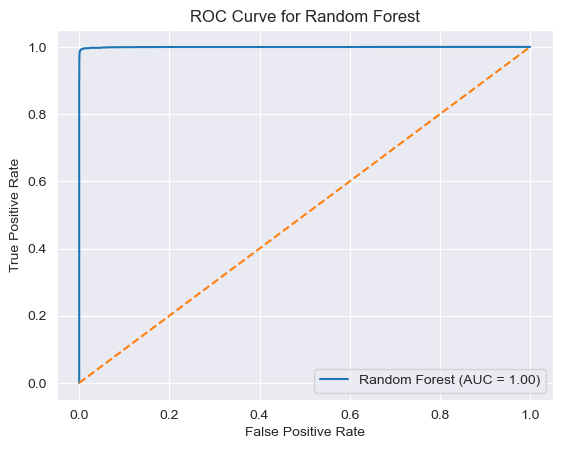

Model Training Time: 5.7802 seconds
Prediction Time: 0.0888 seconds
Train Accuracy: 100.00%
Test Accuracy: 99.35%
Cohen's Kappa: 0.987
Random Forest Classification Report
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3490
           1       0.99      0.99      0.99      4341

    accuracy                           0.99      7831
   macro avg       0.99      0.99      0.99      7831
weighted avg       0.99      0.99      0.99      7831



In [332]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=None,
    n_jobs=-1
)

eval_model(rf_model, X_train, y_train, X_test, y_test)

# Linear SVC Approach

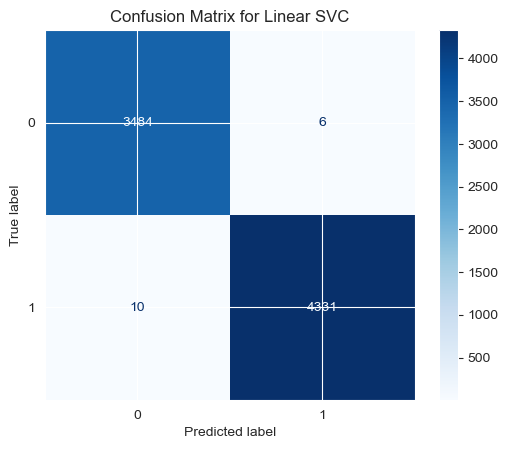

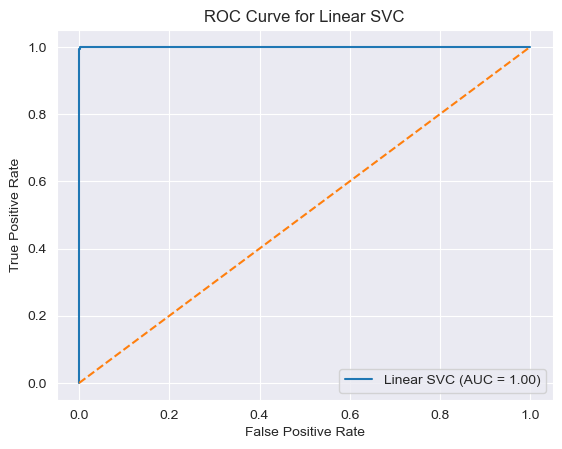

Model Training Time: 0.1532 seconds
Prediction Time: 0.0024 seconds
Train Accuracy: 100.00%
Test Accuracy: 99.80%
Cohen's Kappa: 0.996
Linear SVC Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3490
           1       1.00      1.00      1.00      4341

    accuracy                           1.00      7831
   macro avg       1.00      1.00      1.00      7831
weighted avg       1.00      1.00      1.00      7831



In [333]:
# Initialize, Fit, & Evaluate
svc_model = LinearSVC(random_state=42)
eval_model(svc_model, X_train, y_train, X_test, y_test)

# XGBoost Approach

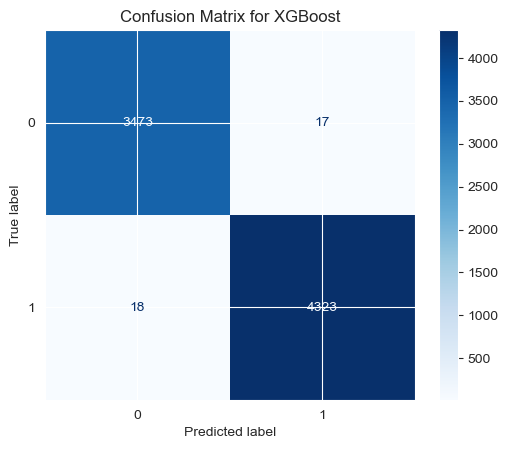

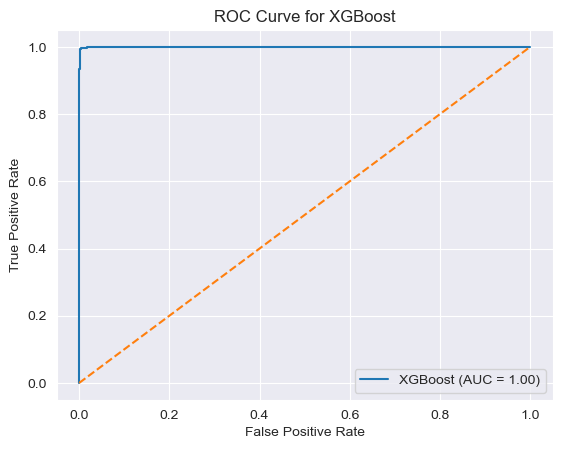

Model Training Time: 28.8279 seconds
Prediction Time: 0.0420 seconds
Train Accuracy: 99.96%
Test Accuracy: 99.55%
Cohen's Kappa: 0.991
XGBoost Classification Report
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3490
           1       1.00      1.00      1.00      4341

    accuracy                           1.00      7831
   macro avg       1.00      1.00      1.00      7831
weighted avg       1.00      1.00      1.00      7831



In [334]:
# Initialize, Fit & Evaluate
xgb_model = xgb.XGBClassifier(random_state=42, eval_metric='logloss')
eval_model(xgb_model, X_train, y_train, X_test, y_test)